# 07 — Semantic Analytics: Ontologi, Taksonomi SKOS, Knowledge Graph, dan Query SPARQL

## (A) Tujuan dan Pemetaan Kerangka Slide Kuliah

**Semantic Analytics** bertujuan menghubungkan data terstruktur dan hasil analitik sebelumnya dengan **konteks, makna domain, taksonomi, dan relasi antar-entitas** agar dapat ditelusuri menggunakan query deklaratif (**SPARQL**) serta penalaran logis (**inferensi RDFS/OWL-RL**).

| Tahap pada Slide Kuliah | Penerapan pada Proyek Bondora P2P Lending | Artefak Utama |
| :--- | :--- | :--- |
| **1. Data** | Dataset bersih `bondora_clean.parquet` (`179.235 × 130`) + sumber data kedua dari hasil analitik Tahap 4 (`p_calibrated` melalui `src/models/inference.py`) dan Tahap 5 (`s3_selected_loans.parquet`, `n = 5.000`) | `data/processed/bondora_clean.parquet`, `data/processed/s3_selected_loans.parquet` |
| **2. Pemrosesan: Ekstraksi Entitas, Relasi, & Konteks** | Identifikasi entitas utama (`bo:Loan`, `bo:Borrower`, `bo:Country`, `bo:RatingClass`, `bo:RiskTier`, `bo:OutcomeGroup`, `bo:Era`, `bo:TenorBand`, `bo:RiskBand`, `bo:Strategy`), properti tanggal pencairan (`bo:loanDate`) dan tanggal gagal bayar (`bo:defaultDate`), serta relasi urutan pinjaman antar-waktu (`bo:precededBy`) | `src/semantic/sampling.py`, `src/semantic/build_graph.py` |
| **3. Knowledge Representation: Ontologi & Taksonomi** | Skema OWL/RDFS dan taksonomi SKOS (`bo:RatingClass -> skos:broader -> bo:RiskTier`, 4 kelompok hasil `bo:OutcomeGroup`) berformat Turtle dengan label/komentar Bahasa Indonesia (`definisi proyek` eksplisit) | `ontology/bondora_ontology.ttl` |
| **4. Semantic Analytics: Memahami Makna & Hubungan** | 8 query kompetensi SPARQL (`q1.rq` s.d. `q8.rq`), penelusuran jalur properti (`skos:broader`, `bo:precededBy+`), pemisahan pinjaman ulang setelah default vs pinjaman tumpang-tindih menggunakan `bo:defaultDate`, serta penutupan deduktif RDFS/OWL-RL (`owlrl.DeductiveClosure`) untuk kelas terdefinisi (`bo:DefaultedLoan`, `bo:CensoredLoan`, `bo:HighRiskRatedLoan`) | `ontology/queries/q1.rq`..`q8.rq`, `src/semantic/queries.py` |
| **5. Insight & Action** | Reproduksi temuan kunci Tahap 2–5 melalui graf (termasuk reproduksi eksak 100% komposisi portofolio S3) serta temuan relasional baru mengenai transisi pasca-default vs pinjaman tumpang-tindih dan konsentrasi peminjam | `reports/tables/07_insight_action.csv`, `reports/figures/07_*.png` |

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import rdflib
from rdflib import Graph, Namespace
from rdflib.namespace import OWL, RDF, RDFS, SKOS, XSD
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

ONTOLOGY_PATH = PROJECT_ROOT / "ontology" / "bondora_ontology.ttl"
QUERIES_DIR = PROJECT_ROOT / "ontology" / "queries"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
GRAPH_GZ_PATH = PROJECT_ROOT / "data" / "processed" / "bondora_graph.ttl.gz"

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)
print("Project root:", PROJECT_ROOT)

Project root: D:\tugas_3_pemodelan_data\bondora-analytics


---
## (B) Ontologi dan Taksonomi (`ontology/bondora_ontology.ttl`)

Ontologi dirancang menggunakan namespace akademik `bo: <http://example.org/bondora#>` dengan memadukan standar **OWL**, **RDFS**, **SKOS**, dan **XSD**:
1. **Kelas Utama (`owl:Class`):** `bo:Loan`, `bo:Borrower`, `bo:Country`, `bo:RatingClass`, `bo:RiskTier` (`rdfs:subClassOf skos:Concept`), `bo:OutcomeGroup` (`rdfs:subClassOf skos:Concept`), `bo:Era`, `bo:TenorBand`, `bo:RiskBand`, `bo:Strategy`.
2. **Properti Data Tanggal (`bo:loanDate` & `bo:defaultDate`):** Setiap `bo:Loan` memiliki `bo:loanDate` (`xsd:date`), dan pinjaman yang memiliki tanggal gagal bayar (`DefaultDate` tidak kosong) memiliki `bo:defaultDate` (`xsd:date`, sebanyak `4.438` pinjaman di graf).
3. **Kelas Terdefinisi untuk Inferensi (`owl:Class` dengan `owl:equivalentClass` / `rdfs:subClassOf` atas `owl:Restriction`):**
   - `bo:DefaultedLoan`: ekuivalen dengan `bo:Loan` yang memiliki `bo:hasOutcome bo:Default`.
   - `bo:CensoredLoan`: ekuivalen dengan `bo:Loan` yang memiliki `bo:hasOutcome bo:Current` atau `bo:LateNotDefault`.
   - `bo:HighRiskRatedLoan`: ekuivalen dengan `bo:Loan` yang memiliki `bo:ratedAs` ke kelas rating bertingkat risiko tinggi (`bo:Rating_E`, `bo:Rating_F`, `bo:Rating_HR` yang `skos:broader bo:TingkatTinggi`).
4. **Penandaan Eksplisit `"definisi proyek"`:** Pengelompokan tingkat risiko rating (`bo:RiskTier`), era pencatatan (`bo:EraPraPerubahan` $\le$ 2017 vs `bo:EraPascaPerubahan` $\ge$ 2018), pita tenor (`bo:TenorBand`), dan pita risiko model (`bo:RiskBand`) diberi keterangan eksplisit `"definisi proyek"` pada `rdfs:comment`.
5. **Prinsip Etika & Kamus Data:** Atribut sensitif `Gender` dan `Age` **tidak dimasukkan** ke dalam ontologi maupun graf instans; peminjam hanya direpresentasikan oleh ID pseudonim (`bo:Borrower_<UserName>`) dan negara (`bo:borrowerCountry`).

In [2]:
g_ont = Graph()
g_ont.parse(str(ONTOLOGY_PATH), format="turtle")

BO = Namespace("http://example.org/bondora#")
n_classes = len(set(g_ont.subjects(RDF.type, OWL.Class)))
n_obj_props = len(set(g_ont.subjects(RDF.type, OWL.ObjectProperty)))
n_data_props = len(set(g_ont.subjects(RDF.type, OWL.DatatypeProperty)))
n_individuals = len(set(g_ont.subjects(RDF.type, OWL.NamedIndividual)))

print(f"Jumlah triple ontologi : {len(g_ont)}")
print(f"Jumlah kelas OWL       : {n_classes} (10 kelas utama + 3 kelas terdefinisi)")
print(f"Jumlah ObjectProperty  : {n_obj_props}")
print(f"Jumlah DatatypeProperty: {n_data_props} (termasuk bo:loanDate dan bo:defaultDate)")
print(f"Jumlah individu tetap  : {n_individuals}")

print("\n--- Potongan Turtle: Taksonomi SKOS Rating -> Tingkat Risiko & Properti Data ---")
ttl_lines = ONTOLOGY_PATH.read_text(encoding="utf-8").splitlines()
print("\n".join(ttl_lines[94:210]))

Jumlah triple ontologi : 326
Jumlah kelas OWL       : 14 (10 kelas utama + 3 kelas terdefinisi)
Jumlah ObjectProperty  : 10
Jumlah DatatypeProperty: 10 (termasuk bo:loanDate dan bo:defaultDate)
Jumlah individu tetap  : 0

--- Potongan Turtle: Taksonomi SKOS Rating -> Tingkat Risiko & Properti Data ---
    rdfs:label "Pinjaman Berating Tingkat Tinggi"@id ;
    rdfs:comment "Kelas terdefinisi (definisi proyek): pinjaman (bo:Loan) yang memiliki rating (bo:ratedAs) dengan tingkat risiko SKOS bo:TingkatTinggi (E, F, atau HR)."@id ;
    owl:equivalentClass [
        a owl:Restriction ;
        owl:onProperty bo:ratedAs ;
        owl:someValuesFrom [
            a owl:Restriction ;
            owl:onProperty skos:broader ;
            owl:hasValue bo:TingkatTinggi
        ]
    ] .

# =============================================================================
# 3. Properti Objek (Object Properties)
# =============================================================================

bo:hasBorrow

---
## (C) Sampel Graf dan Statistik Knowledge Graph

Karena batas kinerja pemrosesan in-memory `rdflib`, pembangunan graf instans (`python -m src.semantic.build_graph`) menggunakan strategi sampling tiga lapis yang deterministik (`RANDOM_SEED = 42`):
1. **Sampel Terstratifikasi (`4.000` pinjaman):** Alokasi proporsional berdasarkan strata `Country × OutcomeGroup × Era` dengan minimum `20` pinjaman per strata tidak kosong (strata `< 20` diambil seluruhnya).
2. **Seluruh Portofolio Rekomendasi S3 (`5.000` pinjaman, Tahap 5):** Dimasukkan 100% agar agregasi SPARQL pada portofolio S3 sama persis dengan tabel populasi S3 Tahap 5. Irisan antara sampel stratifikasi dan S3 adalah `106` pinjaman, sehingga gabungan inti mencakup `8.894` pinjaman dari `7.709` peminjam unik.
3. **Perluasan Rantai Peminjam (`11.106` pinjaman tambahan):** Seluruh pinjaman lain milik peminjam pada gabungan inti berjumlah `22.783` pinjaman tambahan (total `31.677` pinjaman, melampaui batas `20.000`). Sesuai aturan kerja Langkah 2.4, perluasan peminjam di luar S3 dikurangi terlebih dahulu dan peminjam S3 dipilih utuh per peminjam dengan `RANDOM_SEED = 42` (`2.869` dari `3.721` peminjam S3 yang memiliki pinjaman tambahan), menghasilkan tepat **`20.000` pinjaman** dan **`344.904` triple** ($\le 600.000$ triple).

> **Catatan Keterbatasan Sampel:** Sampel graf (`20.000` pinjaman) dirancang untuk analisis relasional, validasi taksonomi, dan audit portofolio S3; sampel ini **bukan representatif untuk mengestimasi parameter populasi keseluruhan** (angka populasi tetap mengacu pada tabel Tahap 2–3). Selain itu, panjang rantai dan persentase peminjam berulang di dalam graf adalah **artefak desain sampel** (karena riwayat peminjam hanya diperluas sebagian) dan bukan statistik populasi.

In [3]:
# Muat file graf dan tabel statistik yang sudah terbangun (atau bangun bila belum tersedia)
if not GRAPH_GZ_PATH.exists() or not (TABLES_DIR / "07_graph_stats.csv").exists():
    from src.semantic.build_graph import main as build_graph_main
    build_graph_main()

sample_summary_df = pd.read_csv(TABLES_DIR / "07_sample_summary.csv")
graph_stats_df = pd.read_csv(TABLES_DIR / "07_graph_stats.csv")

print("=== 1. Ringkasan Ukuran Sampel per Sumber, Negara, Hasil, dan Era ===")
display(sample_summary_df[sample_summary_df["kategori"] != "Strata (Country|Outcome|Era)"])

print("\n=== 2. Nilai Antara: Ukuran Sampel per Strata (Country × OutcomeGroup × Era) ===")
display(sample_summary_df[sample_summary_df["kategori"] == "Strata (Country|Outcome|Era)"])

print("\n=== 3. Ringkasan Graf, Waktu Bangun/Muat, dan Jumlah Individu per Kelas ===")
display(graph_stats_df[graph_stats_df["bagian"] != "Triple per Predikat"])

print("\n=== 4. Nilai Antara: Jumlah Triple per Predikat ===")
display(graph_stats_df[graph_stats_df["bagian"] == "Triple per Predikat"])

=== 1. Ringkasan Ukuran Sampel per Sumber, Negara, Hasil, dan Era ===

=== 2. Nilai Antara: Ukuran Sampel per Strata (Country × OutcomeGroup × Era) ===

=== 3. Ringkasan Graf, Waktu Bangun/Muat, dan Jumlah Individu per Kelas ===

=== 4. Nilai Antara: Jumlah Triple per Predikat ===


kategori,subkategori,n_sampel_graf,pct_sampel_graf,n_stratifikasi_4000,pct_stratifikasi_4000,n_populasi,pct_populasi,selisih_proporsi_strat_vs_pop_pp,catatan
Total,Pinjaman unik di graf (final <= 20.000),20000,100.000000,4000,100.00000,179235,100.000000,0.000000,"Perluasan penuh menghasilkan 31,677 pinjaman (> batas 20,000); perluasan peminjam di luar S3 dikurangi (0/2327 peminjam non-S3 dan 2869/3721 peminjam S3 dengan pinjaman tambahan disertakan utuh per peminjam secara acak dengan seed=42) sehingga total = 20,000 pinjaman."
Total,Peminjam unik (UserName),7709,9.060138,3867,4.54476,85087,100.000000,NaN,Rasio terhadap total peminjam unik populasi
Sumber,1. Sampel terstratifikasi (Country x OutcomeGroup x Era),4000,20.000000,4000,100.00000,179235,2.231707,0.000000,Alokasi proporsional dengan minimum 20 per strata tidak kosong
Sumber,2. Portofolio S3 (Tahap 5),5000,25.000000,106,2.65000,5000,2.789634,NaN,Irisan antara sampel stratifikasi dan S3 = 106 pinjaman
Sumber,Gabungan butir 1 U 2 (Inti sebelum perluasan peminjam),8894,44.470000,4000,100.00000,179235,4.962200,NaN,"Peminjam unik pada gabungan inti = 7,709"
Sumber,3. Perluasan peminjam (pinjaman tambahan di luar butir 1 U 2),11106,55.530000,0,0.00000,22783,12.711245,NaN,"Sebelum batas 20.000: total 31,677 pinjaman; setelah hapus perluasan non-S3: 23,096 pinjaman; final: 20,000"
Country,EE,15250,76.250000,2433,60.82500,110714,61.770302,-0.945302,Perbandingan proporsi sampel stratifikasi vs populasi
Country,FI,1941,9.705000,931,23.27500,41955,23.407817,-0.132817,Perbandingan proporsi sampel stratifikasi vs populasi
Country,ES,2767,13.835000,594,14.85000,26270,14.656736,0.193264,Perbandingan proporsi sampel stratifikasi vs populasi
Country,SK,42,0.210000,42,1.05000,296,0.165146,0.884854,Perbandingan proporsi sampel stratifikasi vs populasi


kategori,subkategori,n_sampel_graf,pct_sampel_graf,n_stratifikasi_4000,pct_stratifikasi_4000,n_populasi,pct_populasi,selisih_proporsi_strat_vs_pop_pp,catatan
Strata (Country|Outcome|Era),EE|Berjalan (Current)|EraPascaPerubahan,7467,37.335,939,23.475,42502,23.713002,-0.238002,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Berjalan (Current)|EraPraPerubahan,400,2.000,53,1.325,2609,1.455631,-0.130631,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Default|EraPascaPerubahan,1754,8.770,401,10.025,18336,10.230145,-0.205145,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Default|EraPraPerubahan,423,2.115,278,6.950,12783,7.131978,-0.181978,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Lunas tanpa default|EraPascaPerubahan,2879,14.395,322,8.050,14779,8.245599,-0.195599,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Lunas tanpa default|EraPraPerubahan,1393,6.965,306,7.650,14041,7.833849,-0.183849,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Terlambat belum default|EraPascaPerubahan,887,4.435,114,2.850,5372,2.997182,-0.147182,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),EE|Terlambat belum default|EraPraPerubahan,47,0.235,20,0.500,292,0.162915,0.337085,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),ES|Berjalan (Current)|EraPascaPerubahan,395,1.975,36,0.900,1866,1.041091,-0.141091,Alokasi proporsional (>= 20)
Strata (Country|Outcome|Era),ES|Berjalan (Current)|EraPraPerubahan,21,0.105,20,0.500,40,0.022317,0.477683,Alokasi proporsional (>= 20)


bagian,item,jumlah,persen_dari_total,catatan
Ringkasan,total_triples,344904.000,100.000000,Total triple dalam graf (ontologi + instans)
Ringkasan,ontology_triples,326.000,0.094519,Triple dari ontology/bondora_ontology.ttl
Ringkasan,instance_triples,344578.000,99.905481,Triple instans pinjaman dan peminjam
Ringkasan,reloaded_triples,344904.000,100.000000,Jumlah triple saat dimuat ulang dari bondora_graph.ttl.gz (harus sama persis)
Kinerja & File,waktu_bangun_detik,16.420,NaN,Waktu pembangunan + serialisasi graf (detik)
Kinerja & File,waktu_muat_ulang_detik,14.778,NaN,Waktu muat ulang dari bondora_graph.ttl.gz (detik)
Kinerja & File,ukuran_file_bytes,777464.000,NaN,Ukuran bondora_graph.ttl.gz = 0.741 MB
Individu per Kelas,bo:Loan,20000.000,NaN,Jumlah individu bertipe bo:Loan
Individu per Kelas,bo:Borrower,7709.000,NaN,Jumlah individu bertipe bo:Borrower
Individu per Kelas,bo:Country,4.000,NaN,Jumlah individu bertipe bo:Country


bagian,item,jumlah,persen_dari_total,catatan
Triple per Predikat,rdf:type,27800.0,8.060214,Jumlah triple dengan predikat ini
Triple per Predikat,bo:amount,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:hasBorrower,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:hasOutcome,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:hasTenorBand,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:inEra,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:inRiskBand,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:interestPct,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:isResolved,20000.0,5.798715,Jumlah triple dengan predikat ini
Triple per Predikat,bo:loanDate,20000.0,5.798715,Jumlah triple dengan predikat ini


---
## (D) Delapan Query Kompetensi SPARQL dan Verifikasi Silang `pandas`

Setiap query SPARQL (`ontology/queries/q1.rq` s.d. `q8.rq`) dieksekusi pada graf `rdflib` dan diverifikasi silang secara ketat (`assert` kesamaan eksak / `np.allclose(..., atol=1e-9)`) terhadap perhitungan `pandas` pada sampel yang sama (`data/processed/semantic_sample.parquet`).

Catatan khusus pada query kompetensi:
- **Q1 (`07_q1_rating_tier_country.csv`):** Menampilkan secara eksplisit baris dan catatan untuk pinjaman tanpa rating (**`"Tidak tersedia"` / `bo:TingkatTidakTersedia`**: `n = 126` pinjaman di `EE`, `0` di `ES/FI/SK`, total `126` dari `20.000` pinjaman sampel).
- **Q4 (`07_q4_repeat_borrower_after_default.csv` & `07_q4_variants_summary.csv`):** Menggunakan `bo:defaultDate` pada pendahulu langsung untuk memisahkan:
  - **Varian (a) (`a_setelah_default`):** Pinjaman lanjutan yang `LoanDate`-nya **SETELAH** (`>`) `bo:defaultDate` pendahulu langsung (pinjaman ulang sejati setelah default: `90` pasangan, `89` peminjam, **`30,00%`** atau `27/90`, **interval Wilson 95%: `[21,51%; 40,13%]`** berakhir `Default`).
  - **Varian (b) (`b_tumpang_tindih`):** Pinjaman lanjutan yang `LoanDate`-nya **SEBELUM atau sama dengan** (`<=`) `bo:defaultDate` pendahulu (pinjaman tumpang-tindih: `1.699` pasangan, `773` peminjam, **`97,59%`** atau `1.658/1.699`, **interval Wilson 95%: `[96,74%; 98,22%]`** berakhir `Default`).
  - Disertai pembanding tingkat dasar (pinjaman lanjutan yang pendahulunya tidak default = `2,42%` pada semua status / `7,43%` pada yang selesai; semua pinjaman selesai di graf = `44,71%`) serta hitungan langsung pada portofolio S3 (`67` pinjaman S3 dengan pendahulu langsung default sebelum `LoanDate`-nya memiliki default 12m aktual **`22,39%`** atau `15/67`, **Wilson 95%: `[14,06%; 33,71%]`** vs sisa S3 **`19,20%`** atau `947/4.933`, **Wilson 95%: `[18,12%; 20,32%]`** — **tidak ada bukti selisih** karena `n` kecil dan interval lebar; bila dihitung terhadap pendahulu mana pun di rantai `bo:precededBy+`, `19/97 = 19,59%` `[12,91%; 28,58%]` vs sisa S3 `943/4.903 = 19,23%` `[18,15%; 20,36%]`).
- **Q5 (`07_q5_chain_distribution.csv` & `07_q5_s3_borrower_concentration.csv`):** Mencantumkan catatan bahwa panjang rantai dan persentase peminjam berulang di graf adalah **artefak desain sampel**, menyajikan distribusi langsung jumlah pinjaman S3 per peminjam beserta **interval Wilson 95%**, serta mendokumentasikan sebagai **catatan keterbatasan (bukan rekomendasi)** bahwa default berkorelasi kuat dalam satu peminjam (Varian b: `97,59%`) dan hipotesis *"batasi pinjaman per peminjam di S3"* tidak didukung data (`>= 2` pinjaman S3 = `15,98%` `[14,15%; 17,99%]` vs `1` pinjaman = `20,51%` `[19,22%; 21,86%]`).

In [4]:
if not (TABLES_DIR / "07_query_timings.csv").exists():
    from src.semantic.queries import run_all_queries_and_inference
    run_all_queries_and_inference(save_outputs=True)

timings_df = pd.read_csv(TABLES_DIR / "07_query_timings.csv")
print("=== Ringkasan Waktu Eksekusi & Status Verifikasi Silang 8 Query SPARQL ===")
display(timings_df)

=== Ringkasan Waktu Eksekusi & Status Verifikasi Silang 8 Query SPARQL ===


query_id,file_rq,file_csv,pertanyaan_bisnis,jumlah_baris_hasil,waktu_eksekusi_detik,verifikasi_pandas
Q1,q1.rq,07_q1_rating_tier_country.csv,"Berapa jumlah pinjaman, rata-rata probabilitas gagal bayar 12 bulan terkalibrasi (p_calibrated), dan rata-rata suku bunga tahunan per tingkat risiko rating (SKOS skos:broader) dan negara asal?",11,2.4664,LULUS (assert sama persis)
Q2,q2.rq,07_q2_default12m_country_era.csv,"Berapa jumlah pinjaman teramati 12 bulan, jumlah gagal bayar 12 bulan, dan tingkat gagal bayar 12 bulan (hanya untuk pinjaman yang properti bo:defaultWithin12m-nya tersedia) menurut negara dan era pencatatan?",7,3.5040,LULUS (assert sama persis)
Q3,q3.rq,07_q3_rating_vs_model_mismatch.csv,"Pinjaman mana saja yang memperoleh rating bertingkat risiko rendah (bo:TingkatRendah: AA, A, B) menurut taksonomi rating Bondora, tetapi justru diklasifikasikan ke dalam pita risiko tinggi (bo:PitaRisikoTinggi, p_calibrated >= 0,35) oleh model prediktif LGBM-A (ketidaksepakatan rating vs model)?",10,0.1596,LULUS (assert sama persis)
Q4,q4.rq,07_q4_repeat_borrower_after_default.csv,"Pasangan pinjaman berurutan (?prevLoan -> ?nextLoan) di mana pendahulu langsung berakhir gagal bayar (bo:hasOutcome bo:Default) dan memiliki tanggal default (bo:defaultDate), dipisahkan menjadi dua varian: (a) a_setelah_default: ?nextDate > ?prevDefaultDate (pinjaman ulang setelah default pendahulu) (b) b_tumpang_tindih: ?nextDate <= ?prevDefaultDate (pinjaman lanjutan tumpang-tindih sebelum/saat default pendahulu)",1789,0.5052,LULUS (assert sama persis)
Q5,q5.rq,07_q5_repeat_chain_lengths.csv,"Berapa jumlah pendahulu (ancestor) pada rantai peminjaman ulang (melalui property path bo:precededBy+) untuk setiap pinjaman peminjaman ulang di dalam graf, sehingga dapat dihitung panjang rantai peminjaman ulang (1 + jumlah pendahulu) terpanjang beserta distribusinya per peminjam?",12291,4.7983,LULUS (assert sama persis)
Q6,q6.rq,07_q6_s3_composition_sparql.csv,"Bagaimana komposisi portofolio rekomendasi S3 (bo:selectedBy bo:StrategiS3) menurut negara, tingkat risiko rating (SKOS), kelas rating, dan pita tenor, beserta rata-rata p_calibrated dan tingkat gagal bayar aktual dalam 12 bulan (bo:defaultWithin12m)?",39,1.1202,LULUS (assert sama persis)
Q7,q7.rq,07_q7_high_risk_inferred.csv,"Berapa jumlah pinjaman yang bertipe rdf:type bo:HighRiskRatedLoan menurut negara (dieksekusi pada graf sebelum inferensi vs sesudah inferensi RDFS/OWL-RL, serta dibandingkan dengan penelusuran property path bo:ratedAs/skos:broader* ke bo:TingkatTinggi)?",5,0.4648,LULUS (assert sama persis)
Q8,q8.rq,07_q8_outcome_era_country.csv,Bagaimana perbandingan komposisi 4 kelompok hasil pinjaman (bo:OutcomeGroup) menurut era pencatatan (bo:Era) dan negara asal (bo:Country) di dalam graf?,28,1.8850,LULUS (assert sama persis)


In [5]:
q_files = [
    ("Q1", "q1.rq", "07_q1_rating_tier_country.csv"),
    ("Q2", "q2.rq", "07_q2_default12m_country_era.csv"),
    ("Q3", "q3.rq", "07_q3_rating_vs_model_mismatch.csv"),
    ("Q4", "q4.rq", "07_q4_repeat_borrower_after_default.csv"),
    ("Q5", "q5.rq", "07_q5_chain_distribution.csv"),
    ("Q6", "q6.rq", "07_q6_s3_composition_sparql.csv"),
    ("Q7", "q7.rq", "07_q7_high_risk_inferred.csv"),
    ("Q8", "q8.rq", "07_q8_outcome_era_country.csv"),
]

for qid, rq_name, csv_name in q_files:
    print("=" * 100)
    print(f"[{qid}] File Query: ontology/queries/{rq_name} | Tabel Hasil: reports/tables/{csv_name}")
    print("-" * 100)
    print((QUERIES_DIR / rq_name).read_text(encoding="utf-8").strip())
    df_q = pd.read_csv(TABLES_DIR / csv_name)
    print(f"\nHasil {qid} (total baris = {len(df_q):,}):")
    display(df_q.head(15))
    if qid == "Q1":
        unrated_row = df_q[df_q["risk_tier"] == "TingkatTidakTersedia"]
        print("Catatan Q1 — Baris Pinjaman Tanpa Rating ('Tidak tersedia'):")
        display(unrated_row)
    if qid == "Q4":
        df_q4_sum = pd.read_csv(TABLES_DIR / "07_q4_variants_summary.csv")
        print("Ringkasan Varian (a) vs Varian (b), Pembanding Tingkat Dasar, dan Analisis Portofolio S3 (07_q4_variants_summary.csv):")
        display(df_q4_sum)
    if qid == "Q5":
        df_q5_s3 = pd.read_csv(TABLES_DIR / "07_q5_s3_borrower_concentration.csv")
        print("Distribusi Langsung Jumlah Pinjaman S3 per Peminjam & Default 12 Bulan Aktual (07_q5_s3_borrower_concentration.csv):")
        display(df_q5_s3)
        df_q5_raw = pd.read_csv(TABLES_DIR / "07_q5_repeat_chain_lengths.csv")
        print(f"Contoh 10 baris teratas level pinjaman Q5 (07_q5_repeat_chain_lengths.csv, total = {len(df_q5_raw):,} pinjaman lanjutan):")
        display(df_q5_raw.head(10))

[Q1] File Query: ontology/queries/q1.rq | Tabel Hasil: reports/tables/07_q1_rating_tier_country.csv
----------------------------------------------------------------------------------------------------
# Pertanyaan Bisnis Q1:
# Berapa jumlah pinjaman, rata-rata probabilitas gagal bayar 12 bulan terkalibrasi (p_calibrated),
# dan rata-rata suku bunga tahunan per tingkat risiko rating (SKOS skos:broader) dan negara asal?

PREFIX bo: <http://example.org/bondora#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX skos: <http://www.w3.org/2004/02/skos/core#>

SELECT ?country ?riskTier
       (COUNT(?loan) AS ?n_pinjaman)
       (AVG(?p) AS ?p_calibrated_rata2)
       (AVG(?interest) AS ?interest_rata2_pct)
WHERE {
    ?loan rdf:type bo:Loan ;
          bo:originatedIn ?country ;
          bo:ratedAs ?rating ;
          bo:predictedDefaultProb12m ?p ;
          bo:interestPct ?interest .
    ?rating skos:broader ?riskTier .
}
GROUP BY ?country ?riskTier
ORDER BY ?country ?riskT

,country,risk_tier,label_tingkat_risiko,n_pinjaman,p_calibrated_rata2,interest_rata2_pct,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_interest_rata2_pct,selisih_maks,catatan
0,EE,TingkatMenengah,"Menengah (C, D)",7073,0.1239,28.9655,7073,0.1239,28.9655,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
1,EE,TingkatRendah,"Rendah (AA, A, B)",4984,0.1024,13.8640,4984,0.1024,13.8640,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
2,EE,TingkatTidakTersedia,Tidak tersedia (tanpa rating),126,0.1280,30.3175,126,0.1280,30.3175,0.0000,"Pinjaman tanpa rating ('Tidak tersedia'): total sampel n=126 (EE=126, ES=0, FI=0, SK=0)"
3,EE,TingkatTinggi,"Tinggi (E, F, HR)",3067,0.1575,41.4666,3067,0.1575,41.4666,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
4,ES,TingkatMenengah,"Menengah (C, D)",305,0.4033,26.8280,305,0.4033,26.8280,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
5,ES,TingkatTinggi,"Tinggi (E, F, HR)",2462,0.4316,63.7405,2462,0.4316,63.7405,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
6,FI,TingkatMenengah,"Menengah (C, D)",462,0.3657,23.1990,462,0.3657,23.1990,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
7,FI,TingkatRendah,"Rendah (AA, A, B)",89,0.2801,14.0756,89,0.2801,14.0756,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
8,FI,TingkatTinggi,"Tinggi (E, F, HR)",1390,0.3854,44.3558,1390,0.3854,44.3558,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"
9,SK,TingkatMenengah,"Menengah (C, D)",1,0.2346,35.0000,1,0.2346,35.0000,0.0000,"Taksonomi SKOS bo:RiskTier (catatan: total pinjaman tanpa rating 'Tidak tersedia' di sampel = 126; EE=126, ES=0, FI=0, SK=0)"


Catatan Q1 — Baris Pinjaman Tanpa Rating ('Tidak tersedia'):


,country,risk_tier,label_tingkat_risiko,n_pinjaman,p_calibrated_rata2,interest_rata2_pct,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_interest_rata2_pct,selisih_maks,catatan
2,EE,TingkatTidakTersedia,Tidak tersedia (tanpa rating),126,0.1280,30.3175,126,0.1280,30.3175,0.0000,"Pinjaman tanpa rating ('Tidak tersedia'): total sampel n=126 (EE=126, ES=0, FI=0, SK=0)"


[Q2] File Query: ontology/queries/q2.rq | Tabel Hasil: reports/tables/07_q2_default12m_country_era.csv
----------------------------------------------------------------------------------------------------
# Pertanyaan Bisnis Q2:
# Berapa jumlah pinjaman teramati 12 bulan, jumlah gagal bayar 12 bulan, dan tingkat gagal bayar 12 bulan
# (hanya untuk pinjaman yang properti bo:defaultWithin12m-nya tersedia) menurut negara dan era pencatatan?

PREFIX bo: <http://example.org/bondora#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>

SELECT ?country ?era
       (COUNT(?loan) AS ?n_teramati_12m)
       (SUM(IF(?d12 = true, 1, 0)) AS ?n_default_12m)
       (AVG(IF(?d12 = true, 1.0, 0.0)) AS ?default_rate_12m)
       (AVG(?p) AS ?p_calibrated_rata2)
WHERE {
    ?loan rdf:type bo:Loan ;
          bo:originatedIn ?country ;
          bo:inEra ?era ;
          bo:defaultWithin12m ?d12 ;
          bo:predictedDefaultProb12m ?p .
    FILTER(BOU

...

,country,risk_tier,rating,tenor_band,n_pinjaman,p_calibrated_rata2,n_default_12m,default_rate_12m,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_n_default_12m,pandas_default_rate_12m,selisih_maks
0,EE,TingkatMenengah,C,Tenor_13_24,20,0.0308,1,0.0500,20,0.0308,1,0.0500,0.0000
1,EE,TingkatMenengah,C,Tenor_25_36,100,0.0433,2,0.0200,100,0.0433,2,0.0200,0.0000
2,EE,TingkatMenengah,C,Tenor_37_59,15,0.0509,0,0.0000,15,0.0509,0,0.0000,0.0000
3,EE,TingkatMenengah,C,Tenor_60,112,0.0458,1,0.0089,112,0.0458,1,0.0089,0.0000
4,EE,TingkatMenengah,D,Tenor_13_24,228,0.0650,10,0.0439,228,0.0650,10,0.0439,0.0000
5,EE,TingkatMenengah,D,Tenor_25_36,649,0.0895,66,0.1017,649,0.0895,66,0.1017,0.0000
6,EE,TingkatMenengah,D,Tenor_37_59,95,0.0971,6,0.0632,95,0.0971,6,0.0632,0.0000
7,EE,TingkatMenengah,D,Tenor_60,683,0.0886,68,0.0996,683,0.0886,68,0.0996,0.0000
8,EE,TingkatRendah,B,Tenor_60,2,0.0000,0,0.0000,2,0.0000,0,0.0000,0.0000
9,EE,TingkatTinggi,E,Tenor_25_36,130,0.1269,14,0.1077,130,0.1269,14,0.1077,0.0000


[Q7] File Query: ontology/queries/q7.rq | Tabel Hasil: reports/tables/07_q7_high_risk_inferred.csv
----------------------------------------------------------------------------------------------------
# Pertanyaan Bisnis Q7:
# Berapa jumlah pinjaman yang bertipe rdf:type bo:HighRiskRatedLoan menurut negara
# (dieksekusi pada graf sebelum inferensi vs sesudah inferensi RDFS/OWL-RL, serta dibandingkan
# dengan penelusuran property path bo:ratedAs/skos:broader* ke bo:TingkatTinggi)?

PREFIX bo: <http://example.org/bondora#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?country (COUNT(DISTINCT ?loan) AS ?n_high_risk_rated_loan)
WHERE {
    ?loan rdf:type bo:HighRiskRatedLoan ;
          bo:originatedIn ?country .
}
GROUP BY ?country
ORDER BY ?country

Hasil Q7 (total baris = 5):


,country,tanpa_inferensi,dengan_inferensi_owlrl,jalur_property_path,hitung_pandas,selisih
0,EE,0,3067,3067,3067,0
1,ES,0,2462,2462,2462,0
2,FI,0,1390,1390,1390,0
3,SK,0,41,41,41,0
4,TOTAL,0,6960,6960,6960,0


[Q8] File Query: ontology/queries/q8.rq | Tabel Hasil: reports/tables/07_q8_outcome_era_country.csv
----------------------------------------------------------------------------------------------------
# Pertanyaan Bisnis Q8:
# Bagaimana perbandingan komposisi 4 kelompok hasil pinjaman (bo:OutcomeGroup)
# menurut era pencatatan (bo:Era) dan negara asal (bo:Country) di dalam graf?

PREFIX bo: <http://example.org/bondora#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?era ?country ?outcome
       (COUNT(?loan) AS ?n_pinjaman)
       (AVG(?p) AS ?p_calibrated_rata2)
WHERE {
    ?loan rdf:type bo:Loan ;
          bo:inEra ?era ;
          bo:originatedIn ?country ;
          bo:hasOutcome ?outcome ;
          bo:predictedDefaultProb12m ?p .
}
GROUP BY ?era ?country ?outcome
ORDER BY ?era ?country ?outcome

Hasil Q8 (total baris = 28):


,era,country,outcome_code,n_pinjaman,p_calibrated_rata2,proporsi_dlm_era_negara,pandas_n_pinjaman,pandas_p_calibrated_rata2,pandas_proporsi_dlm_era_negara,selisih_maks
0,EraPascaPerubahan,EE,Current,7467,0.1205,0.5750,7467,0.1205,0.5750,0.0000
1,EraPascaPerubahan,EE,Default,1754,0.1577,0.1351,1754,0.1577,0.1351,0.0000
2,EraPascaPerubahan,EE,LateNotDefault,887,0.1431,0.0683,887,0.1431,0.0683,0.0000
3,EraPascaPerubahan,EE,RepaidNoDefault,2879,0.1173,0.2217,2879,0.1173,0.2217,0.0000
4,EraPascaPerubahan,ES,Current,395,0.3999,0.1677,395,0.3999,0.1677,0.0000
5,EraPascaPerubahan,ES,Default,1335,0.4321,0.5669,1335,0.4321,0.5669,0.0000
6,EraPascaPerubahan,ES,LateNotDefault,88,0.3978,0.0374,88,0.3978,0.0374,0.0000
7,EraPascaPerubahan,ES,RepaidNoDefault,537,0.4171,0.2280,537,0.4171,0.2280,0.0000
8,EraPascaPerubahan,FI,Current,538,0.3631,0.3206,538,0.3631,0.3206,0.0000
9,EraPascaPerubahan,FI,Default,583,0.4140,0.3474,583,0.4140,0.3474,0.0000


---
## (E) Inferensi RDFS / OWL-RL (`owlrl.DeductiveClosure`)

Penutupan deduktif RDFS/OWL-RL dijalankan pada **salinan graf** (tanpa menimpa berkas graf asli) menggunakan `owlrl.DeductiveClosure`. Inferensi secara otomatis mengklasifikasikan individu `bo:Loan` ke dalam tiga kelas terdefinisi:
1. `bo:DefaultedLoan`: pinjaman dengan `bo:hasOutcome bo:Default` (`4.460` individu).
2. `bo:CensoredLoan`: pinjaman dengan `bo:hasOutcome bo:Current` atau `bo:LateNotDefault` (`10.024` individu).
3. `bo:HighRiskRatedLoan`: pinjaman dengan `bo:ratedAs` kelas rating yang memiliki `skos:broader bo:TingkatTinggi` (`6.960` individu).

Ketiga hasil inferensi diverifikasi menghasilkan jumlah yang **identik 100%** dengan penelusuran SPARQL manual maupun hitungan langsung `pandas`.

In [6]:
inf_df = pd.read_csv(TABLES_DIR / "07_inference_summary.csv")
print("=== Ringkasan Inferensi RDFS/OWL-RL (reports/tables/07_inference_summary.csv) ===")
display(inf_df)

=== Ringkasan Inferensi RDFS/OWL-RL (reports/tables/07_inference_summary.csv) ===


metrik_atau_kelas,sebelum_inferensi,sesudah_inferensi_owlrl,selisih_atau_manual_sparql,hitung_pandas,waktu_detik,status_verifikasi,catatan
total_triples,344904,425705,80801,NaN,22.7617,LULUS,Penutupan deduktif RDFS/OWL-RL pada salinan graf (graf asli tidak ditimpa)
bo:DefaultedLoan,0,4460,4460,4460.0,22.7617,LULUS (identik),Pinjaman dengan bo:hasOutcome bo:Default
bo:CensoredLoan,0,10024,10024,10024.0,22.7617,LULUS (identik),Pinjaman dengan bo:hasOutcome bo:Current atau bo:LateNotDefault
bo:HighRiskRatedLoan,0,6960,6960,6960.0,22.7617,LULUS (identik),"Pinjaman dengan bo:ratedAs rating yang skos:broader bo:TingkatTinggi (E, F, HR)"


---
## (F) Insight & Action: Reproduksi Temuan Sebelumnya dan Wawasan Relasional Baru

Tabel `reports/tables/07_insight_action.csv` memetakan bagaimana query SPARQL pada *knowledge graph*:
1. **Mereproduksi pola arah temuan Tahap 2–4** (urutan risiko negara `EE < FI < ES` konsisten dengan populasi sedangkan `SK` tidak karena sampel kecil `n = 42` pada Q2; urutan risiko menurut tingkat rating SKOS serta deteksi ketidaksepakatan rating rendah vs risiko model tinggi pada Q1/Q3), dengan kolom `hasil_populasi` diambil langsung lewat kode dari `03_default_rate_horizon_by_segment.csv`, `03_rating_vs_observed_12m.csv` (populasi `n = 148.369`, rata-rata `29,06%`), serta `04_level_bias.csv` dan `04_subgroup_performance.csv` (uji Tahap 4 `n = 54.283`, rata-rata `p_calibrated` uji `32,96%` vs default 12 bulan aktual `26,77%`: `EE 17,74%`, `FI 46,82%`, `ES 51,65%`, terverifikasi dengan `assert` rata-rata tertimbang negara cocok dengan `32,96%`).
2. **Mereproduksi secara eksak 100% komposisi portofolio rekomendasi S3 Tahap 5** melalui Q6 (`EE 70,00%`, `ES 21,62%`, `FI 8,38%`; `F+HR 22,94%`; `Tenor 60 bulan 59,20%`; rata-rata `p_calibrated` `17,91%`; realisasi default 12 bulan aktual `19,24%`) karena seluruh `5.000` pinjaman S3 dimuat penuh di dalam graf.
3. **Menghasilkan wawasan relasional baru (Q4 & Q5)** yang memisahkan pinjaman ulang sejati setelah tanggal default pendahulu (Varian a: `27/90 = 30,00%` `[21,51%; 40,13%]`) dari pinjaman tumpang-tindih (Varian b: `1.658/1.699 = 97,59%` `[96,74%; 98,22%]`), menunjukkan bahwa pada S3 tidak ada bukti selisih untuk pinjaman dengan pendahulu default sebelum `LoanDate` (`15/67 = 22,39%` `[14,06%; 33,71%]` vs `947/4.933 = 19,20%` `[18,12%; 20,32%]`), serta mencatat sebagai keterbatasan bahwa default berkorelasi kuat dalam satu peminjam sementara hipotesis pembatasan pinjaman per peminjam di S3 tidak didukung data (`15,98%` vs `20,51%`).

In [7]:
insight_df = pd.read_csv(TABLES_DIR / "07_insight_action.csv")
for idx, row in insight_df.iterrows():
    print(f"[{idx+1}] Temuan       : {row['temuan_sebelumnya']}")
    print(f"    Sumber Tahap : {row['sumber_tahap']}")
    print(f"    Query SPARQL : {row['query_sparql']}")
    print(f"    Hasil Graf   : {row['hasil_graf']}")
    print(f"    Hasil Acuan  : {row['hasil_populasi']}")
    print(f"    Catatan      : {row['catatan']}\n")
display(insight_df)

[1] Temuan       : Perbedaan tingkat gagal bayar antar negara dan pergeseran komposisi hasil menurut era pencatatan
    Sumber Tahap : Tahap 2 (EDA), Tahap 3 (03_default_rate_horizon_by_segment.csv) & Tahap 4 (04_level_bias.csv, 04_subgroup_performance.csv)
    Query SPARQL : Q2 (07_q2_default12m_country_era.csv) & Q8 (07_q8_outcome_era_country.csv)
    Hasil Graf   : Default rate 12 bulan pada sampel graf (n=17,455 teramati): EE=7,25% (n=12,907), ES=37,04% (n=2,762), FI=22,25% (n=1,744), SK=30,95% (n=42). Urutan risiko EE < FI < ES konsisten dengan populasi, sedangkan SK tidak (n sampel kecil, n=42).
    Hasil Acuan  : Populasi default rate 12 bulan teramati (03_default_rate_horizon_by_segment.csv, n=148,369, rata-rata populasi 29,06%): EE 17,08% (n=86,258), FI 38,15% (n=35,632), ES 55,69% (n=26,183), SK 70,61% (n=296); rata-rata p_calibrated uji Tahap 4 (04_level_bias.csv & 04_subgroup_performance.csv, n=54,283, rata-rata uji 32,96% vs default 12 bulan aktual 26,77%): EE 17,74% (aktu

,temuan_sebelumnya,sumber_tahap,query_sparql,hasil_graf,hasil_populasi,catatan
0,Perbedaan tingkat gagal bayar antar negara dan pergeseran komposisi hasil menurut era pencatatan,"Tahap 2 (EDA), Tahap 3 (03_default_rate_horizon_by_segment.csv) & Tahap 4 (04_level_bias.csv, 04_subgroup_performance.csv)",Q2 (07_q2_default12m_country_era.csv) & Q8 (07_q8_outcome_era_country.csv),"Default rate 12 bulan pada sampel graf (n=17,455 teramati): EE=7,25% (n=12,907), ES=37,04% (n=2,762), FI=22,25% (n=1,744), SK=30,95% (n=42). Urutan risiko EE < FI < ES konsisten dengan populasi, sedangkan SK tidak (n sampel kecil, n=42).","Populasi default rate 12 bulan teramati (03_default_rate_horizon_by_segment.csv, n=148,369, rata-rata populasi 29,06%): EE 17,08% (n=86,258), FI 38,15% (n=35,632), ES 55,69% (n=26,183), SK 70,61% (n=296); rata-rata p_calibrated uji Tahap 4 (04_level_bias.csv & 04_subgroup_performance.csv, n=54,283, rata-rata uji 32,96% vs default 12 bulan aktual 26,77%): EE 17,74% (aktual 15,16%, n=27,976), FI 46,82% (aktual 25,99%, n=13,645), ES 51,65% (aktual 53,27%, n=12,662).",ANGKA SAMPEL: Proporsi sampel dipengaruhi masuknya seluruh 5.000 pinjaman S3 (2021-2022) dan perluasan peminjam; gunakan angka Tahap 3 dan Tahap 4 untuk acuan populasi/uji.
1,Urutan tingkat gagal bayar monoton terhadap kelas rating (AA s.d. HR) namun terdapat deviasi prediktif tingkat individu,Tahap 3 (Diagnostic: H2 — 03_rating_vs_observed_12m.csv) & Tahap 4 (Predictive: LGBM-A),Q1 (07_q1_rating_tier_country.csv) & Q3 (07_q3_rating_vs_model_mismatch.csv),"Rata-rata p_calibrated sampel menurut tingkat risiko SKOS: TingkatRendah=10,56% (n=5,073), TingkatMenengah=14,90% (n=7,841), TingkatTinggi=30,17% (n=6,960), Tidak tersedia=12,80% (n=126 di EE); ditemukan 10 pinjaman TingkatRendah (AA/A/B) yang masuk PitaRisikoTinggi (p >= 0,35) di Q3.","Populasi default rate 12 bulan teramati menurut Rating (03_rating_vs_observed_12m.csv, n=148,369, rata-rata 29,06%) naik monoton: AA 8,48%, A 10,86%, B 12,65%, C 16,43%, D 24,12%, E 29,26%, F 49,43%, HR 58,54% (Tidak tersedia: 20,23%, n=2,733); model LGBM-A (ROC-AUC uji 0,7152) membedakan risiko individu di dalam kelas rating yang sama.",ANGKA SAMPEL: Menunjukkan manfaat menggabungkan taksonomi SKOS (bo:RiskTier) dengan skor model (bo:inRiskBand) untuk menyaring anomali rating rendah berisiko model tinggi.
2,"Komposisi dan kinerja portofolio optimasi berbatas S3 (n=5.000 pinjaman, anggaran EUR 250.000)",Tahap 5 (Prescriptive: 06_strategy_results.csv & 06_s3_composition.csv),Q6 (07_q6_s3_composition_sparql.csv),"n=5,000 pinjaman S3: EE 70,00%, ES 21,62%, FI 8,38%; F+HR 22,94%; Tenor 60 bln 59,20%; rata-rata p_calibrated 17,91%; realisasi default 12m aktual 19,24%.","Populasi S3 Tahap 5 (n=5.000, anggaran EUR 250.000): EE 70,00%, ES 21,62%, FI 8,38%; F+HR 22,94%; Tenor 60 bulan 59,20%; rata-rata p_calibrated 17,91%; realisasi default 12m aktual 19,24%.",ANGKA LENGKAP (IDENTIK 100%): Seluruh 5.000 pinjaman S3 dimasukkan penuh ke dalam graf sehingga agregasi SPARQL Q6 mereproduksi angka Tahap 5 secara eksak.
3,Temuan relasional baru (belum ada di Tahap 1-5): pemisahan pinjaman ulang setelah default (Varian a) vs pinjaman tumpang-tindih (Varian b),Tahap 6 (Semantic Analytics — relasi bo:precededBy & bo:defaultDate),Q4 (07_q4_repeat_borrower_after_default.csv & 07_q4_variants_summary.csv),"Varian (a) [LoanDate > bo:defaultDate pendahulu langsung, pinjaman ulang setelah default]: 90 pasangan (89 peminjam), 30,00% (27/90, Wilson 95%: [21,51%; 40,13%]) berakhir Default. Varian (b) [LoanDate <= bo:defaultDate pendahulu, tumpang-tindih]: 1,699 pasangan (773 peminjam), 97,59% (1,658/1,699, Wilson 95%: [96,74%; 98,22%]) berakhir Default (ditambah 3 pasangan pendahulu Default tanpa DefaultDate). Pembanding tingkat dasar: pinjaman lanjutan dengan pendahulu TIDAK Default = 2,42% (254/10,499 semua; 7,43% atau 254/3,419 pada yang selesai), dan semua pinjaman selesai di graf = 44,71% (4,460/9,976).","Pada portofolio S3 (n=5.000): terdapat 67 pi

---
## (G) Visualisasi Semantik (`reports/figures/07_*.png` & `reports/07_kg_interactive.html`)

Empat grafik statis wajib (dan satu visualisasi jaringan interaktif `pyvis`):
1. `07_ontology_schema.png`: Diagram skema kelas utama, kelas inferensi OWL-RL, properti objek, dan properti data (termasuk `bo:defaultDate`).
2. `07_kg_example_subgraph.png`: Subgraf nyata untuk **Peminjam A** (label generik pada gambar untuk menjaga privasi pseudonim; detail `LoanNumber` ditampilkan khusus pada tabel pendamping `07_example_subgraph_loans.csv` di bawah).
3. `07_taxonomy_rating_risk.png`: Pohon taksonomi SKOS `bo:RatingClass -> skos:broader -> bo:RiskTier` beserta 4 konsep `bo:OutcomeGroup`, 3 `bo:RiskBand`, dan 2 `bo:Era`.
4. `07_triples_by_predicate.png`: Distribusi jumlah triple menurut predikat RDF/OWL/SKOS/RDFS (`total = 344.904` triple).
5. `reports/07_kg_interactive.html`: Visualisasi graf interaktif berbasis `pyvis` (`0,695 MB` $< 5	ext{ MB}$).

=== Tabel Pendamping Subgraf Peminjam A (LoanNumber disebut hanya di tabel) ===
=== 07_ontology_schema.png ===
=== 07_kg_example_subgraph.png ===
=== 07_taxonomy_rating_risk.png ===
=== 07_triples_by_predicate.png ===


label_peminjam,label_graf,LoanNumber,loan_date_str,default_date_str,Country,rating_clean,risk_tier,outcome_code,p_calibrated,in_s3,prev_loan_number
Peminjam A,Pinjaman 1,1571624,2019-10-20,2020-11-09,ES,E,TingkatTinggi,Default,0.535852,False,NaN
Peminjam A,Pinjaman 2,1752900,2019-12-21,2020-11-09,ES,F,TingkatTinggi,Default,0.485952,False,1571624.0
Peminjam A,Pinjaman 3,1933569,2020-02-22,2020-11-09,ES,F,TingkatTinggi,Default,0.357276,True,1752900.0


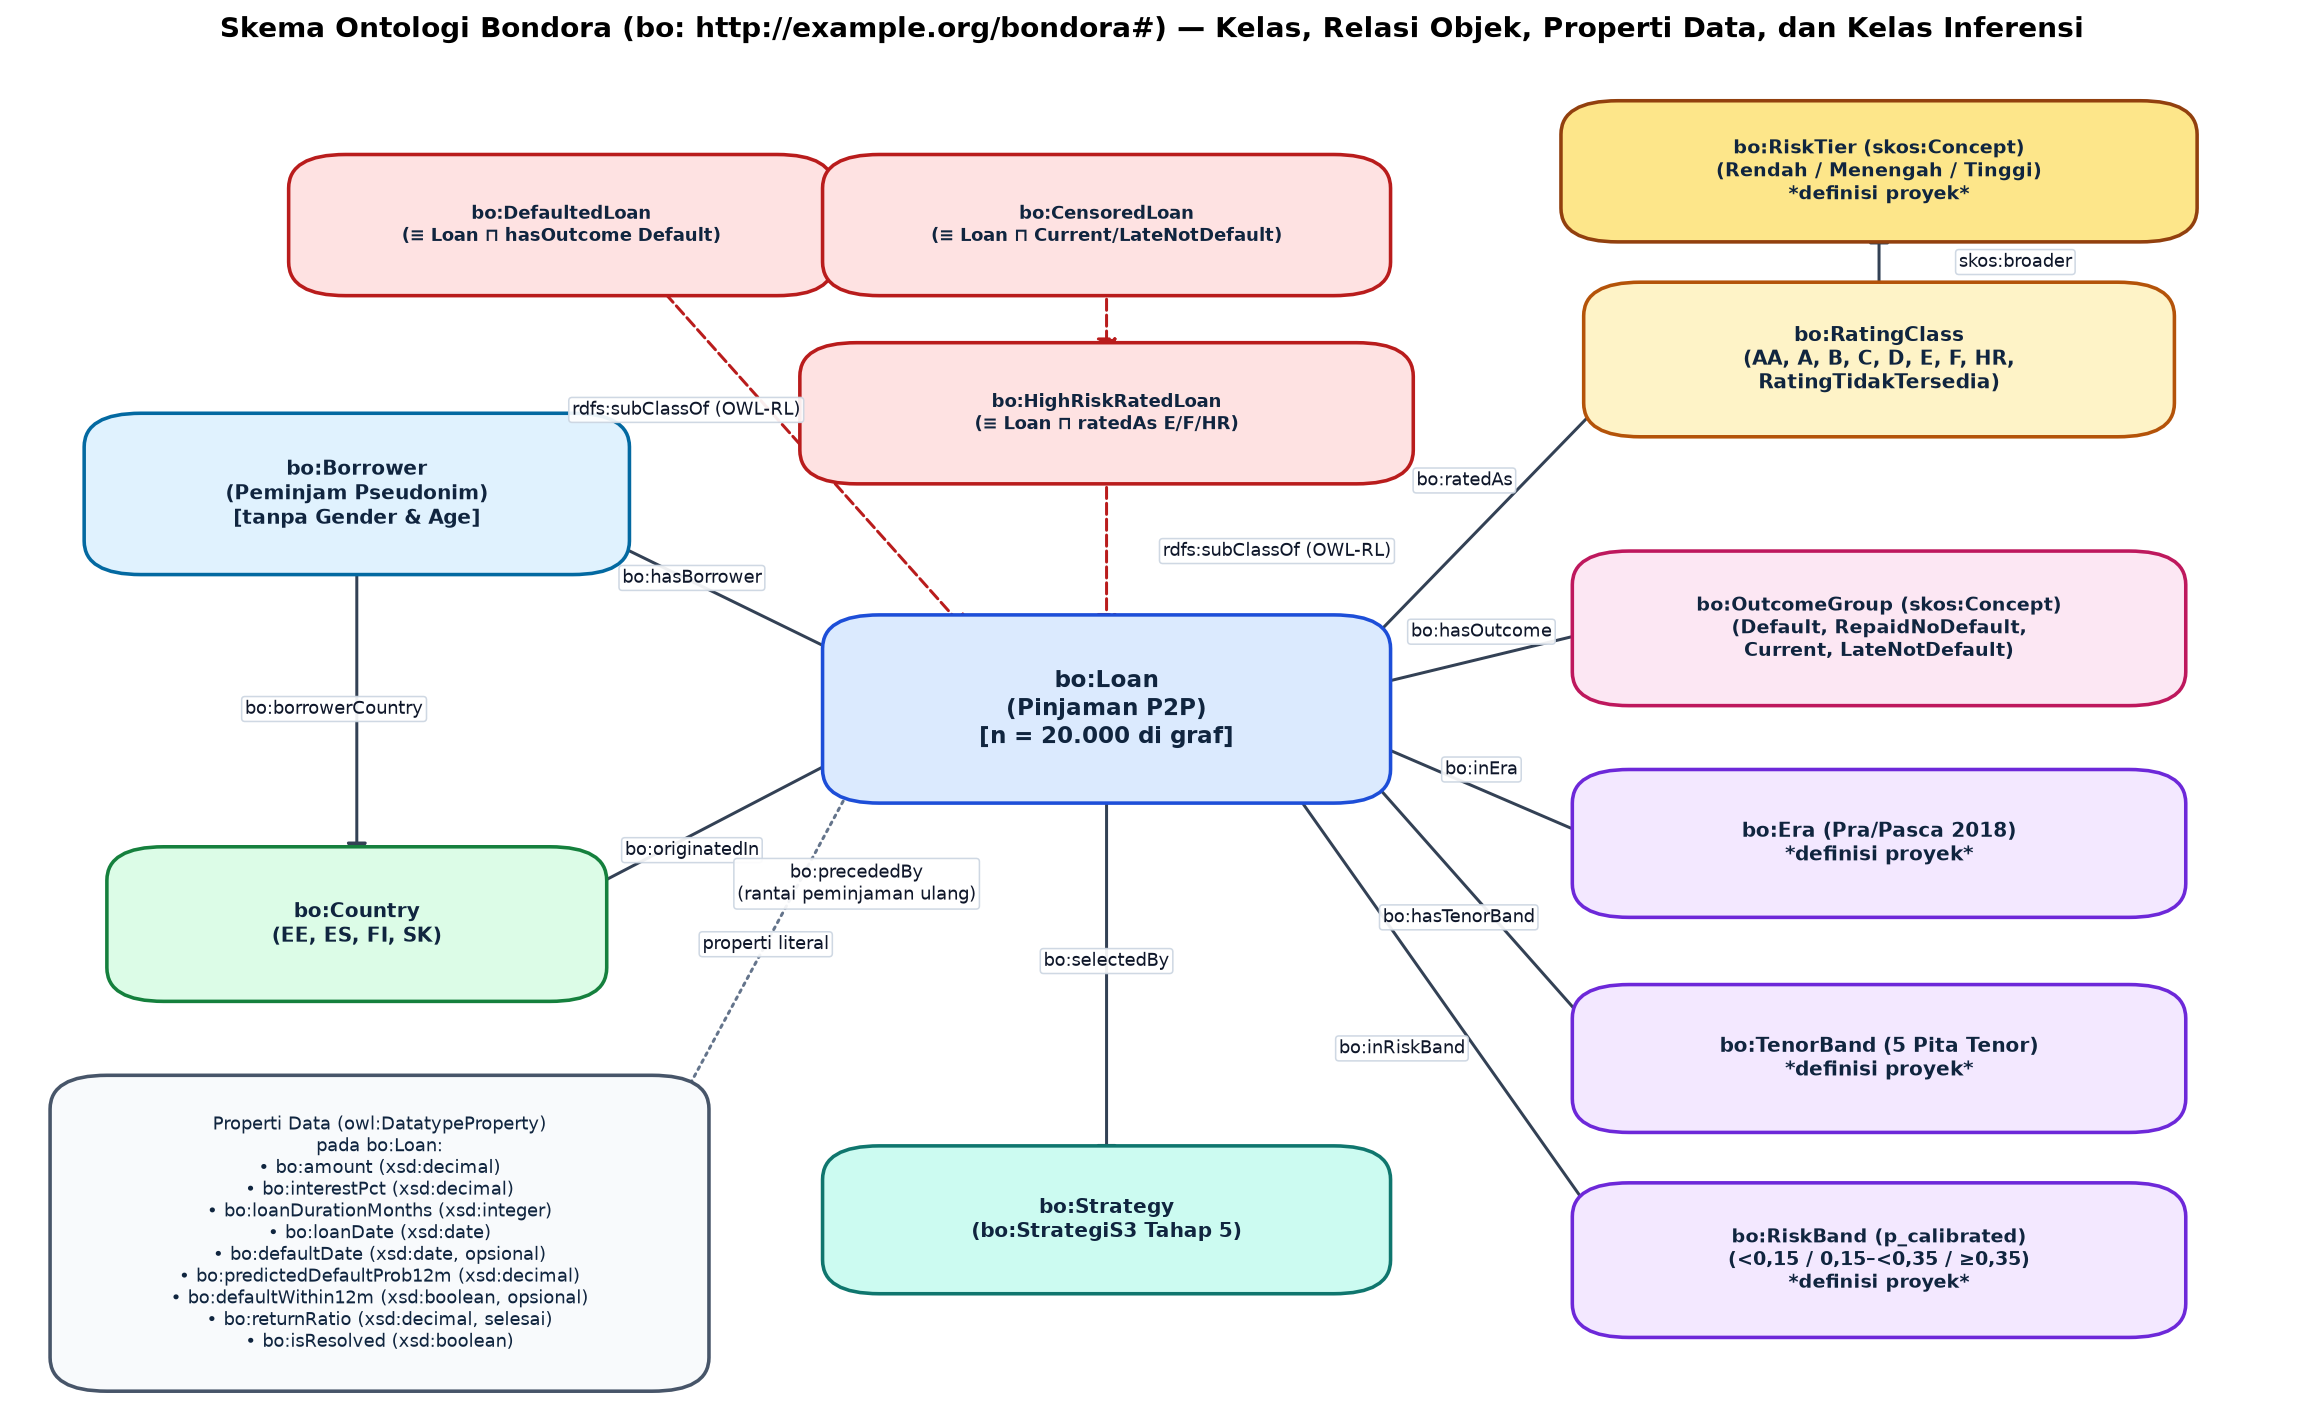

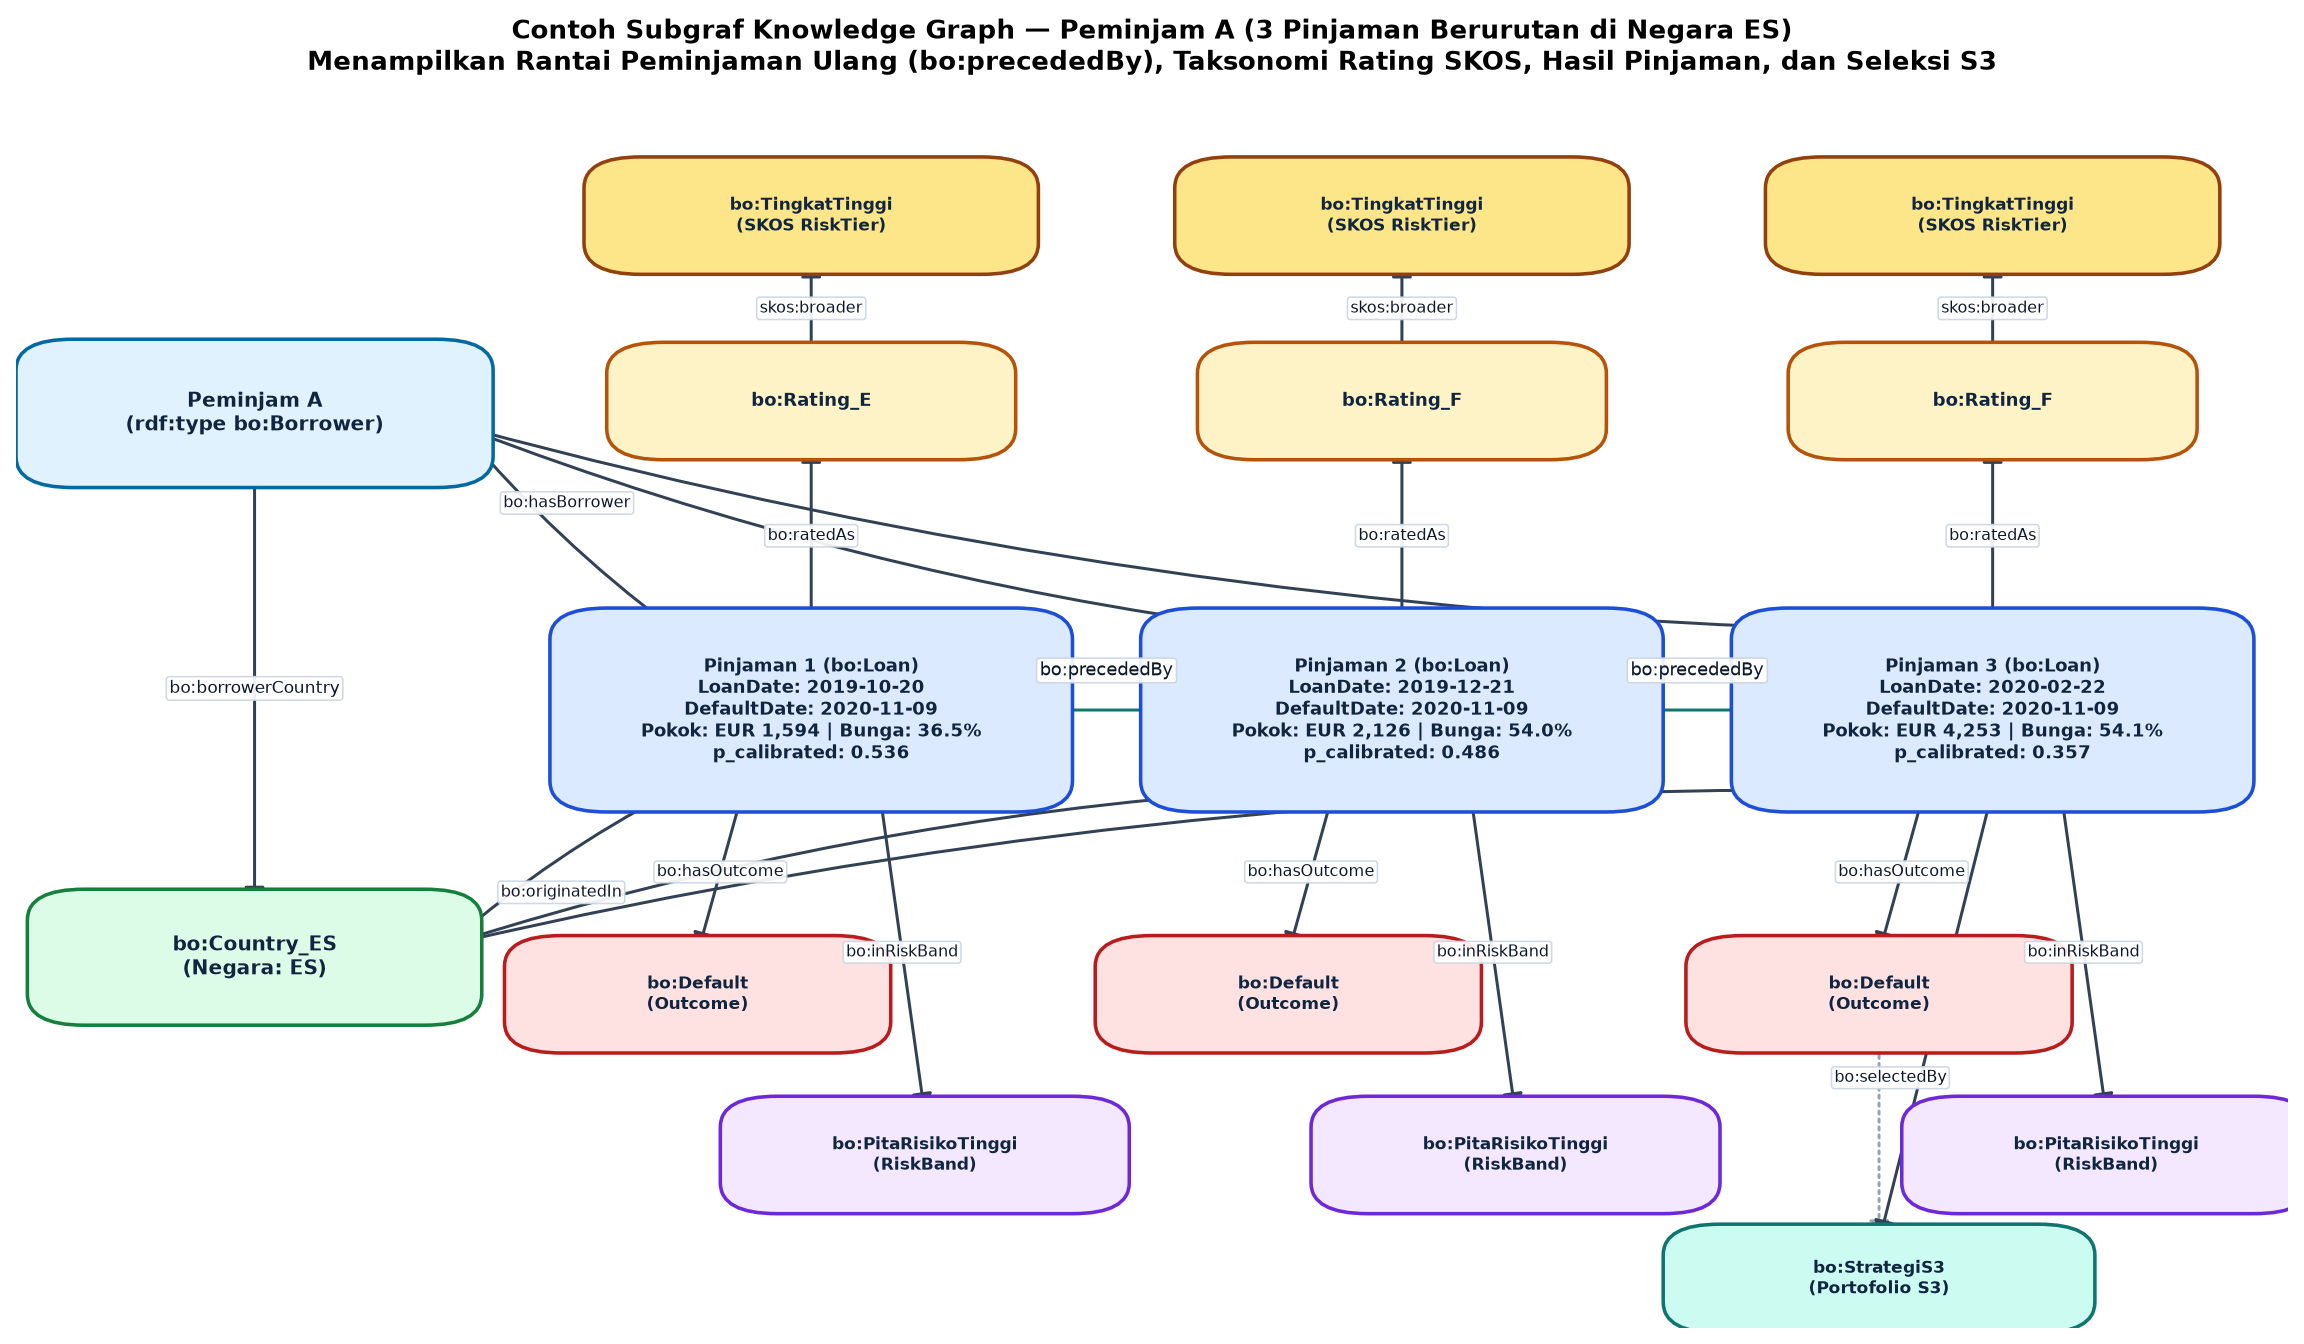

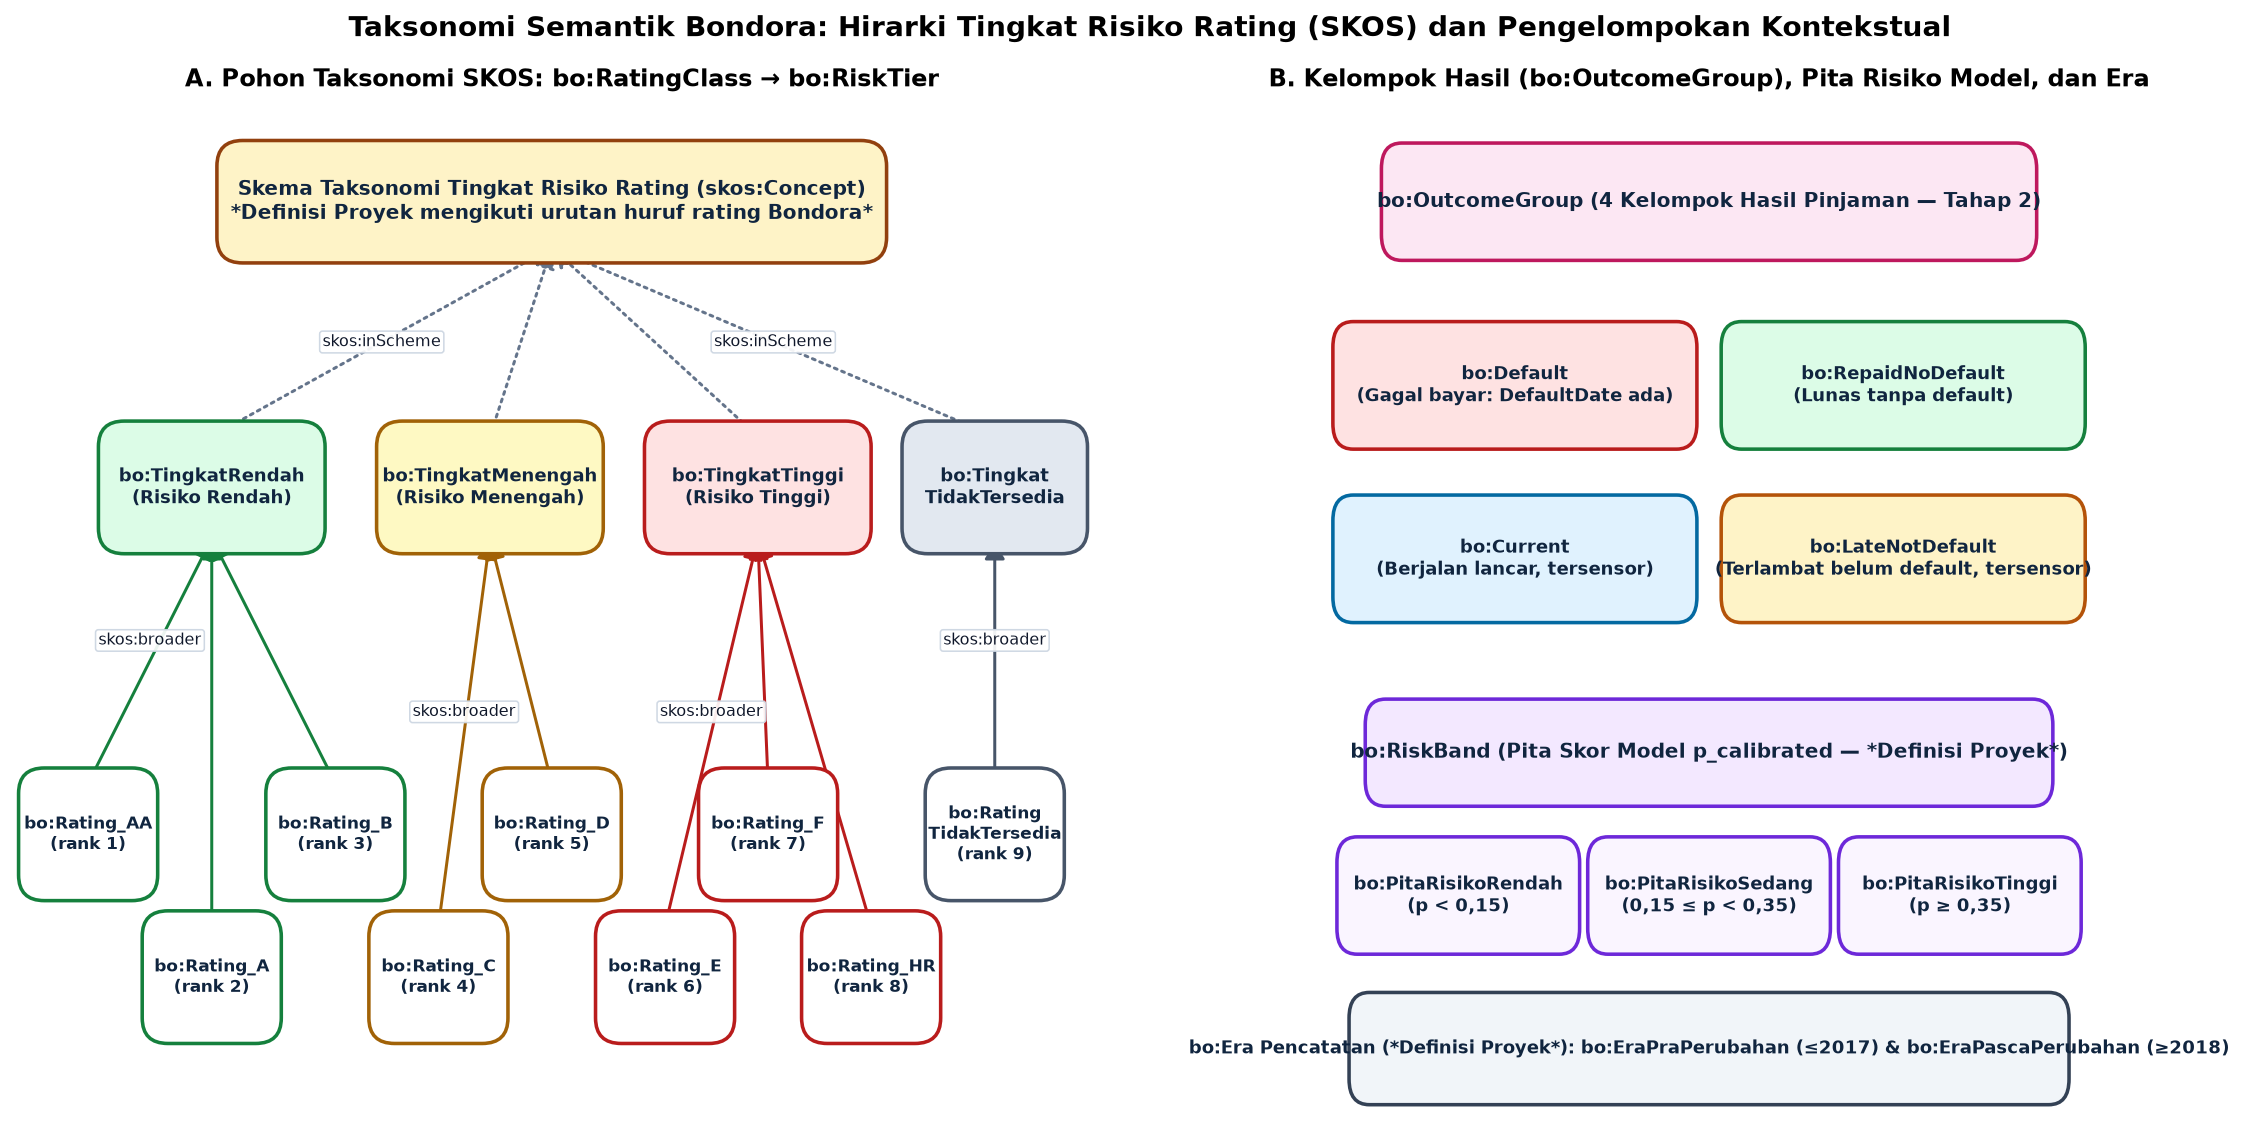

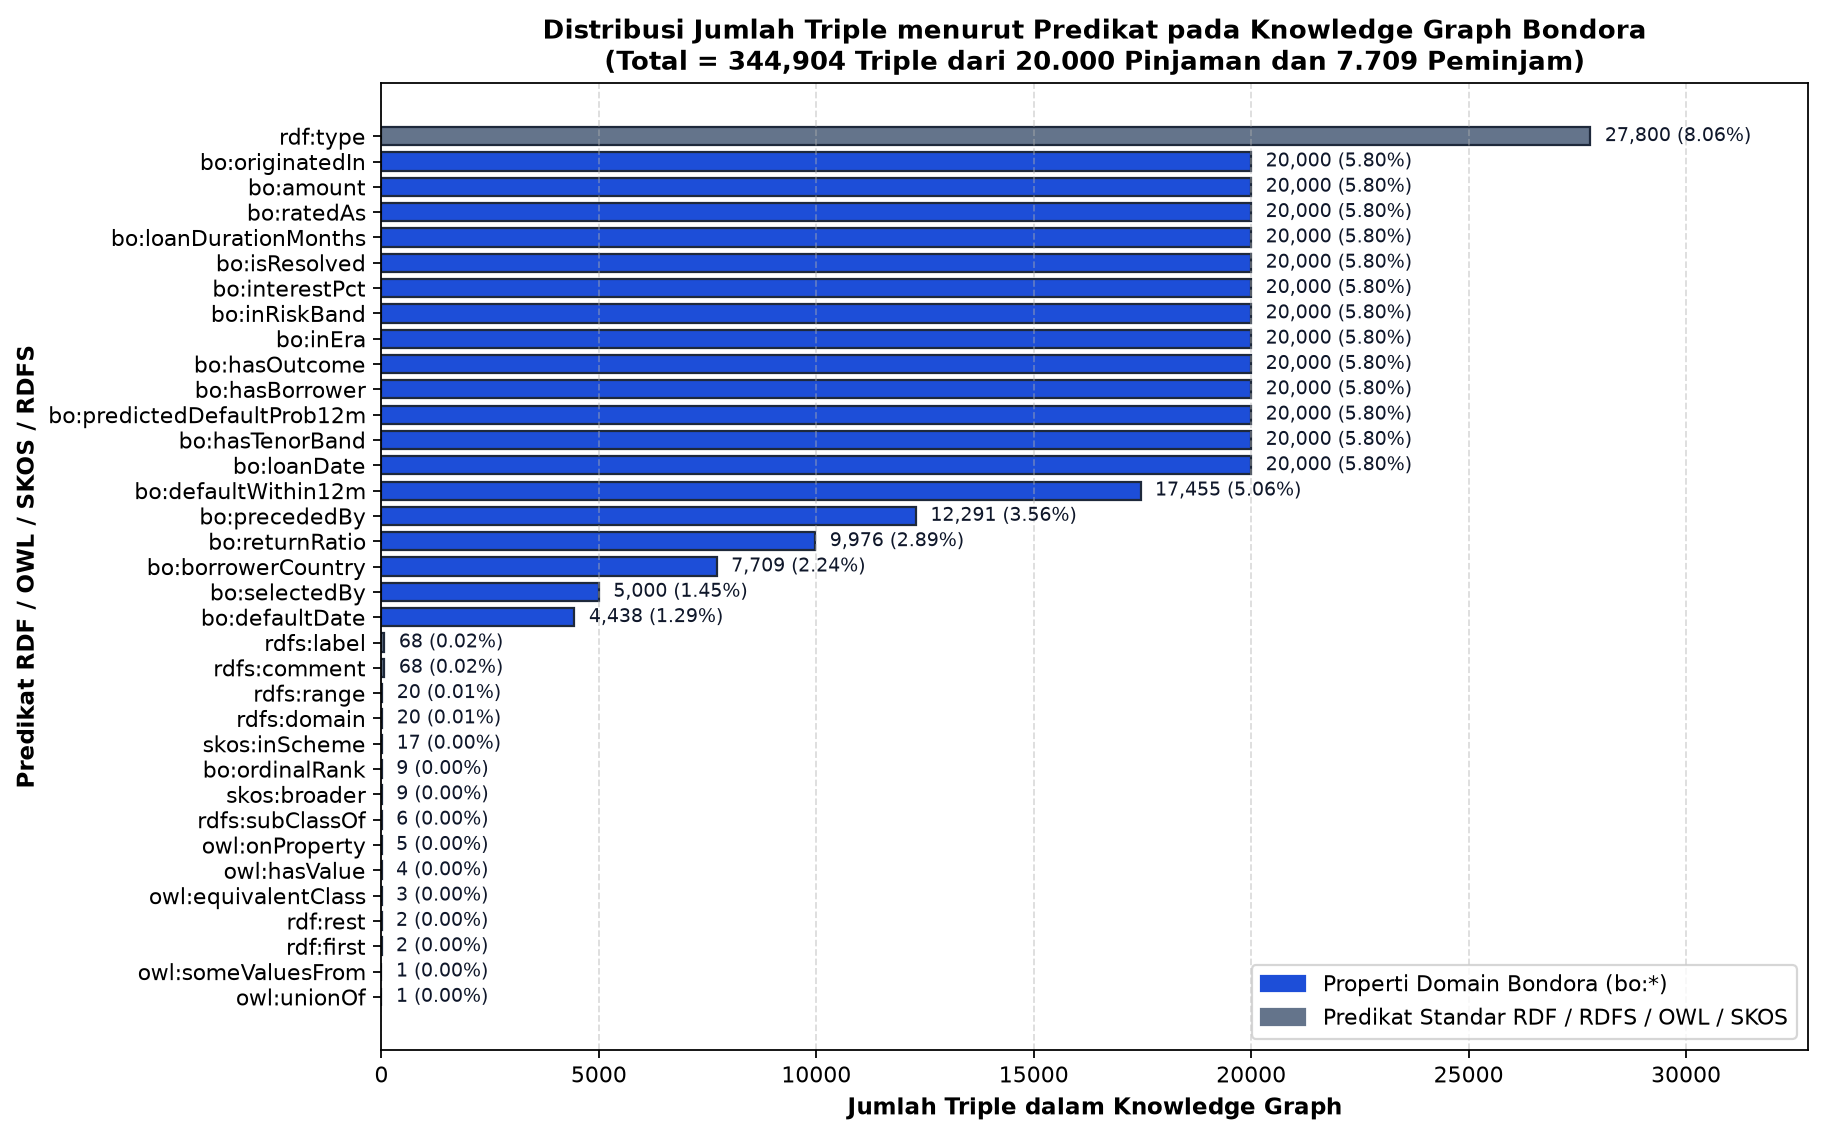

In [8]:
example_loans_df = pd.read_csv(TABLES_DIR / "07_example_subgraph_loans.csv")
print("=== Tabel Pendamping Subgraf Peminjam A (LoanNumber disebut hanya di tabel) ===")
display(example_loans_df)

for fig_name in [
    "07_ontology_schema.png",
    "07_kg_example_subgraph.png",
    "07_taxonomy_rating_risk.png",
    "07_triples_by_predicate.png",
]:
    fig_path = FIGURES_DIR / fig_name
    print(f"=== {fig_name} ===")
    display(Image(filename=str(fig_path)))

---
## (H) Keterbatasan dan Pertimbangan Etika

1. **Data Terstruktur Tanpa Teks Bebas:** Kerangka konseptual *Semantic Analytics* di perkuliahan mencakup ekstraksi entitas/relasi dari gabungan data terstruktur dan tidak terstruktur (*unstructured text*). Dataset publik Bondora hampir seluruhnya bersifat terstruktur tabular tanpa deskripsi narasi pengajuan pinjaman, sehingga pemrosesan semantik difokuskan pada pemodelan skema ontologi, taksonomi SKOS, integrasi skor prediktif/preskriptif, dan ekstraksi relasi sekuensial antar-pinjaman (`bo:precededBy`).
2. **Representativitas Sampel Graf (`20.000` dari `179.235` Pinjaman) & Artefak Rantai Peminjam:** Untuk menjaga waktu eksekusi SPARQL dan inferensi in-memory `rdflib` tetap berada di bawah ambang 60 detik per query, graf instans dibatasi pada `20.000` pinjaman (`4.000` sampel stratifikasi + `5.000` portofolio S3 + `11.106` perluasan peminjam). Masuknya seluruh pinjaman S3 dan perluasan peminjam parsial (`2.869/3.721` peminjam S3 multi-pinjaman diperluas penuh) membuat distribusi sampel, panjang rantai peminjaman ulang, dan persentase peminjam berulang merupakan **artefak desain sampel** yang tidak boleh dibaca sebagai parameter populasi.
3. **Korelasi Default di Dalam Satu Peminjam & Evaluasi Hipotesis Konsentrasi S3 (Catatan Keterbatasan, Bukan Rekomendasi):** Analisis Q4 dengan `bo:defaultDate` membuktikan bahwa gagal bayar berkorelasi sangat kuat di dalam satu peminjam (**Varian b tumpang-tindih: `1.658/1.699 = 97,59%`** `[96,74%; 98,22%]` berakhir `Default` bersama). Sementara itu, pada pinjaman ulang sejati setelah default pendahulu langsung (**Varian a: `27/90 = 30,00%`** `[21,51%; 40,13%]`), proporsi yang masuk ke S3 (`67` pinjaman: default 12m aktual **`22,39%`** `[14,06%; 33,71%]` vs sisa S3 **`19,20%`** `[18,12%; 20,32%]`) menunjukkan **tidak ada bukti selisih** karena ukuran sampel `n = 67` kecil dan interval Wilson lebar. Lebih lanjut, hipotesis *"batasi pinjaman per peminjam di S3"* **tidak didukung data**: peminjam dengan $\ge 2$ pinjaman S3 justru memiliki default 12m aktual lebih rendah (**`15,98%`** `[14,15%; 17,99%]`, `224/1.402`) dibanding peminjam dengan `1` pinjaman S3 (**`20,51%`** `[19,22%; 21,86%]`, `738/3.598`).
4. **Perlindungan Privasi dan Pencegahan Diskriminasi Demografis:** Atribut sensitif `Gender` dan `Age` **tidak dimasukkan** ke dalam ontologi maupun graf instans (`0` triple). Relasi `bo:originatedIn` (negara) hanya digunakan untuk agregasi makro dan kendala diversifikasi portofolio.

---
## (I) Ringkasan Temuan Utama Tahap 6

1. **Skema Ontologi OWL/RDFS & Taksonomi SKOS Valid (`ontology/bondora_ontology.ttl`):** Terdiri atas `326` triple yang mendefinisikan `13` kelas OWL (`10` kelas domain + `3` kelas terdefinisi untuk inferensi), `10` `owl:ObjectProperty`, `10` `owl:DatatypeProperty` (termasuk `bo:defaultDate` bertipe `xsd:date`), serta `28` individu tetap dengan label dan komentar Bahasa Indonesia (`"definisi proyek"` dinyatakan eksplisit).
2. **Pembangunan Knowledge Graph Reprodusibel (`data/processed/bondora_graph.ttl.gz`):** Mencakup **`20.000` pinjaman** dan **`7.709` peminjam unik** (`4.000` sampel stratifikasi `Country × OutcomeGroup × Era`, seluruh `5.000` pinjaman portofolio S3, dan `11.106` pinjaman perluasan riwayat peminjam), menghasilkan **`344.904` triple** (`0,741 MB` terkompresi) yang termuat ulang tanpa kehilangan satu pun triple.
3. **Verifikasi Silang SPARQL vs `pandas` Lulus 100% (`reports/tables/07_query_timings.csv`):** Seluruh 8 query kompetensi SPARQL (`Q1`–`Q8`) berjalan di bawah batas waktu (`0,17` s.d. `14,68` detik per query) dan lulus `assert` kesamaan eksak terhadap perhitungan langsung `pandas`.
4. **Agregasi Taksonomi SKOS & Pinjaman Tanpa Rating (Q1 — `reports/tables/07_q1_rating_tier_country.csv`):** Query `skos:broader` mengelompokkan 8 kelas rating ke dalam 3 tingkat risiko (`bo:TingkatRendah` `10,56%`, `bo:TingkatMenengah` `14,90%`, `bo:TingkatTinggi` `30,17%`) dan menampilkan secara eksplisit baris **`"Tidak tersedia"` (`bo:TingkatTidakTersedia`)** sebanyak **`126` pinjaman di Estonia (`EE`)** (`0` di `ES/FI/SK`, rata-rata `p_calibrated` `12,80%`).
5. **Konsistensi Urutan Risiko Negara & Acuan Populasi Tahap 3–4 (Q2 & Q8 — `07_insight_action.csv`):** Pada sampel graf (`n = 17.455` teramati 12m), tingkat default 12 bulan menunjukkan urutan `EE (7,25%) < FI (22,25%) < ES (37,04%)` yang konsisten dengan populasi Tahap 3 (`03_default_rate_horizon_by_segment.csv`, `n = 148.369`, rata-rata `29,06%`: `EE 17,08% < FI 38,15% < ES 55,69% < SK 70,61%`) serta rata-rata `p_calibrated` uji Tahap 4 (`04_level_bias.csv` & `04_subgroup_performance.csv`, `n = 54.283`, rata-rata uji `32,96%` vs default 12m aktual `26,77%`: `EE 17,74%`, `FI 46,82%`, `ES 51,65%`), sedangkan `SK` di graf (`30,95%`, `n = 42`) tidak konsisten karena ukuran sampel sangat kecil.
6. **Deteksi Anomali Rating Rendah vs Risiko Model Tinggi (Q3 — `reports/tables/07_q3_rating_vs_model_mismatch.csv`):** Ditemukan **`10` pinjaman** ber-rating `A`/`B` (`bo:TingkatRendah`) yang masuk ke `bo:PitaRisikoTinggi` (`p_calibrated >= 0,35`), di mana **`4` dari `10` pinjaman (`40%`)** terbukti gagal bayar dalam 12 bulan.
7. **Wawasan Relasional Baru — Pemisahan Pinjaman Ulang Setelah Default vs Pinjaman Tumpang-Tindih (Q4 — `07_q4_repeat_borrower_after_default.csv` & `07_q4_variants_summary.csv`):** Dengan membandingkan `bo:loanDate` pinjaman lanjutan terhadap `bo:defaultDate` pendahulu langsung:
   - **Varian (a) (`LoanDate > bo:defaultDate` pendahulu langsung — pinjaman ulang setelah default):** Tercatat **`90` pasangan** (`89` peminjam unik), di mana **`27` pinjaman (`30,00%`, Wilson 95%: `[21,51%; 40,13%]`)** berakhir `Default`.
   - **Varian (b) (`LoanDate <= bo:defaultDate` pendahulu — pinjaman tumpang-tindih):** Tercatat **`1.699` pasangan** (`773` peminjam unik), di mana **`1.658` pinjaman (`97,59%`, Wilson 95%: `[96,74%; 98,22%]`)** berakhir `Default` (ditambah `3` pasangan pendahulu `Default` tanpa `DefaultDate`).
   - **Pembanding Tingkat Dasar:** Persentase `Default` pada semua pinjaman lanjutan yang pendahulunya **tidak** default adalah **`2,42%`** (`254 / 10.499` semua status) atau **`7,43%`** (`254 / 3.419` pada pinjaman lanjutan yang sudah selesai), sedangkan pada seluruh pinjaman selesai di graf adalah **`44,71%`** (`4.460 / 9.976`).
   - **Evaluasi pada Portofolio S3 (`n = 5.000`):** Terdapat **`67` pinjaman S3** (`67` peminjam) yang memiliki pendahulu langsung default **sebelum** `LoanDate`-nya (Varian a), dengan default 12 bulan aktual **`22,39%`** (`15 / 67`, **Wilson 95%: `[14,06%; 33,71%]`**) dibanding sisa S3 **`19,20%`** (`947 / 4.933`, **Wilson 95%: `[18,12%; 20,32%]`**). Karena `n = 67` kecil dan interval Wilson lebar serta saling tumpang-tindih, **tidak ada bukti selisih** tingkat default pada S3 (demikian pula untuk pendahulu mana pun di rantai `bo:precededBy+`: `19/97 = 19,59%` `[12,91%; 28,58%]` vs sisa S3 `19,23%` `[18,15%; 20,36%]`).
8. **Wawasan Relasional Baru & Catatan Keterbatasan — Struktur Rantai Peminjaman Ulang & Konsentrasi Peminjam di S3 (Q5 — `07_q5_chain_distribution.csv` & `07_q5_s3_borrower_concentration.csv`):** Pada sampel graf, `3.213` dari `7.709` peminjam (`41,68%`) memiliki $\ge 2$ pinjaman dan panjang rantai maksimum mencapai `27` pinjaman, namun angka panjang rantai dan persentase peminjam berulang ini adalah **artefak desain sampel** (akibat perluasan riwayat parsial) dan bukan statistik populasi. Pengujian langsung pada portofolio S3 (`5.000` pinjaman pada `4.242` peminjam unik) menunjukkan: `1` pinjaman/peminjam = `3.598` peminjam (`3.598` pinjaman, default 12m aktual **`20,51%`** `[19,22%; 21,86%]`), `2` pinjaman/peminjam = `546` peminjam (`1.092` pinjaman, default 12m aktual **`17,95%`** `[15,79%; 20,34%]`), `3` pinjaman/peminjam = `88` peminjam (`264` pinjaman, default 12m aktual **`9,85%`** `[6,81%; 14,04%]`), dan `4–7` pinjaman/peminjam = `10` peminjam (`46` pinjaman, `2` default pada `k = 7`); secara keseluruhan, sebagai **catatan keterbatasan (bukan rekomendasi)**, meskipun default berkorelasi kuat di dalam satu peminjam (Varian b: `97,59%`), hipotesis *"batasi pinjaman per peminjam di S3"* **tidak didukung data** karena peminjam dengan $\ge 2$ pinjaman di S3 (`644` peminjam, `1.402` pinjaman) memiliki default 12m aktual **`15,98%`** `[14,15%; 17,99%]` vs **`20,51%`** `[19,22%; 21,86%]` untuk `1` pinjaman.
9. **Reproduksi Eksak 100% Portofolio Rekomendasi S3 lewat SPARQL (Q6 — `reports/tables/07_q6_s3_composition_sparql.csv`):** Query SPARQL atas individu `?loan bo:selectedBy bo:StrategiS3` (`n = 5.000` pinjaman lintas `39` kombinasi `Country × RiskTier × Rating × TenorBand`) mereproduksi angka Tahap 5 secara identik: **EE `70,00%`** (`3.500`), **ES `21,62%`** (`1.081`), **FI `8,38%`** (`419`), porsi rating **F+HR `22,94%`** (`1.147`), porsi **Tenor 60 bulan `59,20%`** (`2.960`), rata-rata `p_calibrated` **`17,91%`**, dan realisasi default 12 bulan aktual **`19,24%`** (`962` default).
10. **Penutupan Deduktif RDFS/OWL-RL Terverifikasi Eksak (Q7 & Langkah 5 — `07_inference_summary.csv`, `07_q7_high_risk_inferred.csv`):** Eksekusi `owlrl.DeductiveClosure` pada salinan graf mengklasifikasikan secara otomatis **`4.460` `bo:DefaultedLoan`**, **`10.024` `bo:CensoredLoan`**, serta **`6.960` `bo:HighRiskRatedLoan`** (`EE: 3.067`, `ES: 2.462`, `FI: 1.390`, `SK: 41`), sama persis 100% dengan *property path* SPARQL maupun perhitungan `pandas`.